# ML-03 — Frame Your Lane as an ML Task

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/irene1407/ML-1/blob/main/work/notebooks/w02_ml_task_framing.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../../data/raw/content_refresh_anonymized.csv")

print("Dataset shape:", df.shape)

display(df.head(10))

Dataset shape: (30000, 44)


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7
5,content_d4084a4bc775,client_f369cb89fc,720.0,1.00,HIGH,1.05,keyword article,transactional,3080.0,18178.0,...,15000-25000,0.03,8.5,0.00,25.00,0.0,good,page_1,down,-38.9
6,content_9a34b442b552,client_8722616204,0.0,0.00,LOW,0.00,keyword article,informational,3059.0,20810.0,...,15000-25000,0.00,7.0,0.00,0.00,0.0,low,page_1,down,-92.3
7,content_a63219c6e95a,client_19581e27de,590.0,0.44,MEDIUM,0.64,keyword article,commercial,NaN,NaN,...,NaN,0.06,21.2,3.57,7.14,0.0,moderate,page_3_5,stable,0.6
8,content_5e6c160719bc,client_6208ef0f77,0.0,0.00,LOW,0.00,keyword article,informational,3807.0,24228.0,...,15000-25000,0.09,46.0,5.88,6.25,0.0,excellent,page_3_5,down,-58.8
9,content_c27558df2b0c,client_19581e27de,0.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,NaN,0.16,4.9,0.00,0.00,0.0,moderate,page_1,down,-29.2


In [3]:
print(df.columns.tolist())

df.info()

['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 44 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   content_id          

In [4]:
print(df.isnull().sum().sort_values(ascending=False).head(15))

provider_used        21438
word_count            7699
char_count            7699
word_count_tier       7699
char_count_tier       7699
model_used            5733
trend_pct             3388
competition_level     2610
search_volume         2468
cpc                   2468
competition           2468
main_intent           2374
scroll_rate            125
content_type             0
client_id                0
dtype: int64


In [5]:
display(df[['avg_position', 'ctr']].describe())

,avg_position,ctr
count,30000.00000,30000.000000
mean,16.34238,0.510733
std,15.21679,3.279162
min,0.00000,0.000000
25%,6.20000,0.000000
50%,10.80000,0.070000
75%,22.30000,0.290000
max,245.00000,100.000000


In [6]:
print("Rows with avg_position = 0:", (df['avg_position'] == 0).sum())
print("Missing avg_position:", df['avg_position'].isnull().sum())
print("Missing ctr:", df['ctr'].isnull().sum())

Rows with avg_position = 0: 1205
Missing avg_position: 0
Missing ctr: 0


In [7]:
# Remove rows where average position is 0
analysis_df = df[df['avg_position'] > 0].copy()

print("Original rows:", len(df))
print("Rows available for analysis:", len(analysis_df))

display(analysis_df[['avg_position', 'ctr']].describe())

Original rows: 30000
Rows available for analysis: 28795


,avg_position,ctr
count,28795.000000,28795.000000
mean,17.026268,0.519662
std,15.152439,3.232606
min,0.100000,0.000000
25%,6.700000,0.000000
50%,11.400000,0.080000
75%,22.900000,0.300000
max,245.000000,100.000000


In [10]:
import matplotlib.pyplot as plt

In [8]:
# Calculate Spearman correlation
correlation = analysis_df['avg_position'].corr(
    analysis_df['ctr'],
    method='spearman'
)

print("Spearman correlation:", correlation)

Spearman correlation: -0.23421722156193886


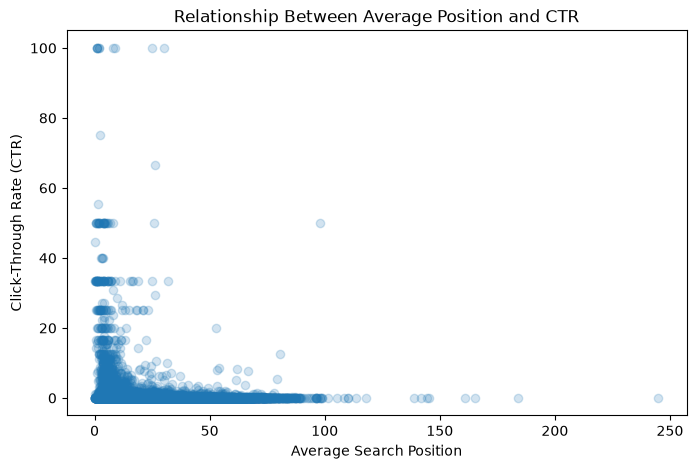

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_df['avg_position'],
    analysis_df['ctr'],
    alpha=0.2
)

plt.xlabel('Average Search Position')
plt.ylabel('Click-Through Rate (CTR)')
plt.title('Relationship Between Average Position and CTR')

plt.show()

In [12]:
# Group content by average search position
analysis_df['position_group'] = pd.cut(
    analysis_df['avg_position'],
    bins=[0, 3, 10, 20, 50, float('inf')],
    labels=['1-3', '4-10', '11-20', '21-50', '50+']
)

# Compare CTR across groups
group_summary = analysis_df.groupby(
    'position_group', observed=True
)['ctr'].agg(['count', 'mean', 'median'])

display(group_summary)

,count,mean,median
position_group,,,
1-3,1141,2.714303,0.00
4-10,11842,0.651045,0.16
11-20,7273,0.323443,0.10
21-50,7225,0.222345,0.03
50+,1314,0.150784,0.00


## ML Task Framing

### 1. Task Type
Signal Analysis.

### 2. Target / Proxy
No prediction target is defined for this initial analysis.
We investigate the relationship between average search position
and click-through rate (CTR).

### 3. Success Metric
- Spearman correlation: -0.234
- Group-wise average and median CTR.
These help measure the strength and direction of the relationship.

### 4. Unit of Analysis
One row represents one pseudonymized content item.
The dataset contains 30,000 content items, of which 28,795
have valid average-position data for this analysis.

### 5. Why ML Instead of a Fixed Rule?
A fixed rule cannot fully capture variations in CTR across
different content items and ranking positions. Analysing
historical data helps uncover patterns across thousands of items.
However, this exploratory analysis does not yet establish that
a predictive ML model is necessary.

### 6. Self-Check
- Excluded rows where avg_position = 0.
- Checked missing values.
- Used Spearman correlation to examine the relationship.
- Compared CTR across ranking groups.
- Correlation does not imply causation.

## 1. My lane as an ML task (type)

*Classification, clustering, ranking, or scoring — which one, and why?*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 2. Target or proxy

*What would you predict? Where does that label come from — observed outcome or a defined rule?*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. Success metric

*One metric you can defend. What number means 'good'?*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. The unit of analysis, as a real dataframe

*Load your lane's slice and show it: one row = one what?*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 5. Why ML beats a fixed rule here

*What makes the pattern too messy for an if-statement?*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.